# Classification and Feature Selection Using Synthetic Gene-Labeled Data

## Executive Summary

High-dimensional biological datasets can present challenges for machine learning because large numbers of features may contain redundant or irrelevant information. Feature selection and regularization are two approaches used to address these challenges.

This project explores these techniques using a synthetic classification dataset generated with scikit-learn's `make_classification()`. The dataset contains 500 observations, 100 numerical features, and three target classes. Of the 100 features, 20 were generated as informative and 10 as redundant.

Although the features are labeled as genes for illustrative purposes, the dataset does not contain actual RNA-seq measurements or represent biological gene-expression distributions.

The analysis compares Gaussian Naive Bayes, L1- and L2-regularized Logistic Regression, and Gradient Boosting using the full feature set. It then evaluates whether selecting 20 features using an ANOVA F-test changes the classification performance of Gaussian Naive Bayes and Gradient Boosting.

### Key Workflow Steps

1. **Synthetic Data Generation:** Generate 500 observations with 100 numerical features and three classification targets.
2. **Preprocessing:** Create a stratified 80/20 train/test split and fit StandardScaler using training data only.
3. **Baseline Classification:** Evaluate four classifiers using all 100 features.
4. **Feature Selection:** Apply SelectKBest with an ANOVA F-test to select 20 features using the training data.
5. **Model Comparison:** Compare Gaussian Naive Bayes and Gradient Boosting before and after feature selection.
6. **Visualization:** Examine confusion matrices and Gradient Boosting feature importances.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Global Plotting Configuration
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 10

print("All dependencies loaded successfully.")

All dependencies loaded successfully.


In [2]:
# 1. Simulate RNA-Seq Expression Data (500 samples, 100 features)
X_raw, y = make_classification(
    n_samples=500,
    n_features=100,
    n_informative=20,
    n_redundant=10,
    n_classes=3,
    random_state=42
)

# 2. Convert to DataFrame and assign gene headers
feature_names = [f"GENE_{i+1:03d}" for i in range(100)]
df_features = pd.DataFrame(X_raw, columns=feature_names)

# 3. Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    df_features, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Standard Scaling (Fit on Train, Transform on Test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Set Shape: {X_train_scaled.shape}")
print(f"Test Set Shape:     {X_test_scaled.shape}")

Training Set Shape: (400, 100)
Test Set Shape:     (100, 100)


In [3]:
# Evaluate baseline classifiers using all 100 simulated features
models_full = {
    "Gaussian Naive Bayes": GaussianNB(),

    "L1 Logistic Regression (Lasso)": LogisticRegression(
        solver="saga",
        penalty="l1",
        C=0.1,
        max_iter=5000,
        random_state=42
    ),

    "L2 Logistic Regression (Ridge)": LogisticRegression(
        solver="lbfgs",
        C=0.1,
        max_iter=5000,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

In [4]:

# Train and evaluate baseline models using all 100 simulated features
full_results = {}

for name, model in models_full.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    full_results[name] = accuracy_score(y_test, preds)

# Display baseline model accuracy
df_full_res = pd.DataFrame(
    list(full_results.items()),
    columns=["Model", "Full Feature Accuracy"]
)

df_full_res


C:\Users\sfnor\miniconda3\envs\ds_main\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\sfnor\miniconda3\envs\ds_main\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,Model,Full Feature Accuracy
0,Gaussian Naive Bayes,0.61
1,L1 Logistic Regression (Lasso),0.61
2,L2 Logistic Regression (Ridge),0.54
3,Gradient Boosting,0.63


## Feature Selection via ANOVA F-Test

ANOVA F-test feature selection was used to rank the 100 simulated features according to their statistical association with the target classes. The `SelectKBest` method retained the 20 highest-scoring features.

The selector was fitted using only the training data and training labels, then applied to the held-out test data. This avoids using test-set information to determine which features are selected.

The selected features are not necessarily the same 20 features designated as informative during synthetic data generation. The experiment evaluates whether a smaller feature subset improves classification accuracy, rather than identifying biologically meaningful genes.

In [5]:
# Select top 20 features using training data
selector = SelectKBest(score_func=f_classif, k=20)
X_train_best = selector.fit_transform(X_train_scaled, y_train)
X_test_best = selector.transform(X_test_scaled)

# Get selected gene names
selected_mask = selector.get_support()
selected_genes = np.array(feature_names)[selected_mask]

# 2. Retrain Best Models
gnb_filtered = GaussianNB().fit(X_train_best, y_train)
gb_filtered = GradientBoostingClassifier(random_state=42).fit(X_train_best, y_train)

# 3. Predict & Score
acc_gnb_filtered = accuracy_score(y_test, gnb_filtered.predict(X_test_best))
acc_gb_filtered = accuracy_score(y_test, gb_filtered.predict(X_test_best))

print("=== FILTERED MODEL ACCURACY (TOP 20 GENES) ===")
print(f"Filtered Gaussian Naive Bayes:  {acc_gnb_filtered:.2%}")
print(f"Filtered Gradient Boosting:     {acc_gb_filtered:.2%}")

=== FILTERED MODEL ACCURACY (TOP 20 GENES) ===
Filtered Gaussian Naive Bayes:  64.00%
Filtered Gradient Boosting:     66.00%


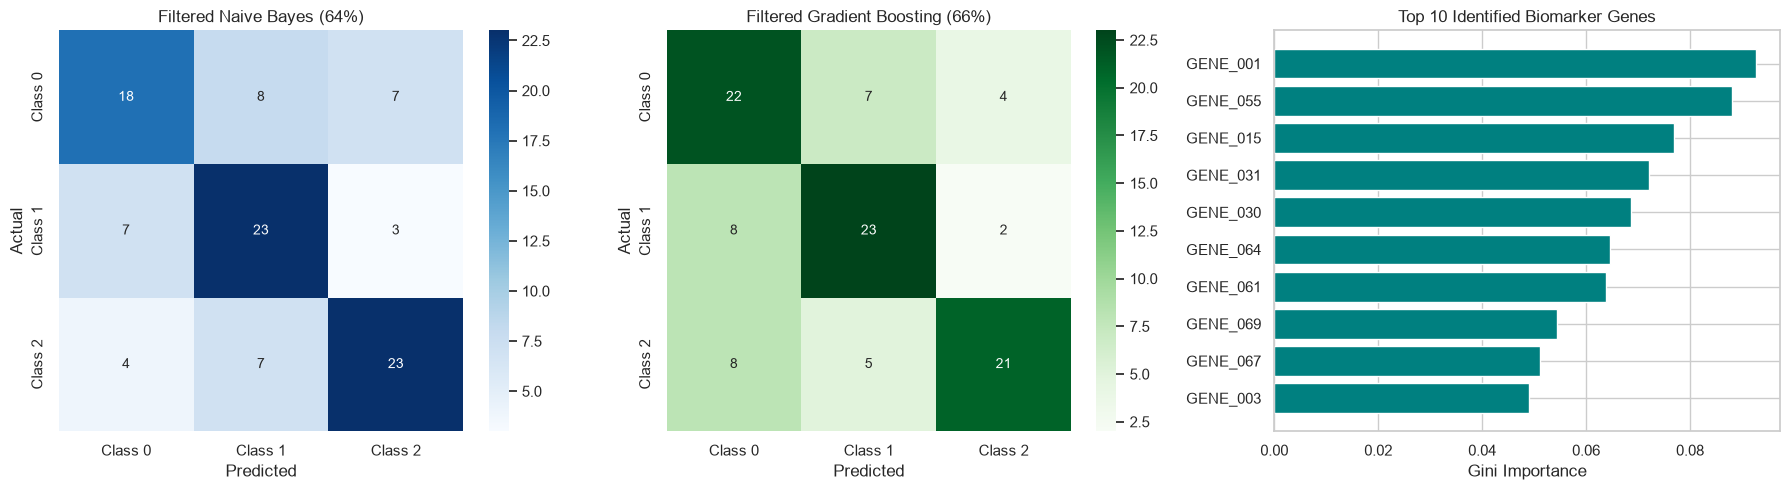

In [6]:
# Create Side-by-Side Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Naive Bayes Confusion Matrix
cm_gnb = confusion_matrix(y_test, gnb_filtered.predict(X_test_best))
sns.heatmap(cm_gnb, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Class 0', 'Class 1', 'Class 2'],
            yticklabels=['Class 0', 'Class 1', 'Class 2'])
axes[0].set_title(f'Filtered Naive Bayes ({acc_gnb_filtered:.0%})')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Plot 2: Gradient Boosting Confusion Matrix
cm_gb = confusion_matrix(y_test, gb_filtered.predict(X_test_best))
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Class 0', 'Class 1', 'Class 2'],
            yticklabels=['Class 0', 'Class 1', 'Class 2'])
axes[1].set_title(f'Filtered Gradient Boosting ({acc_gb_filtered:.0%})')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

# Plot 3: Biomarker Feature Importances
importances = gb_filtered.feature_importances_
top_indices = importances.argsort()[-10:]

axes[2].barh(range(10), importances[top_indices], color='teal', align='center')
axes[2].set_yticks(range(10))
axes[2].set_yticklabels(selected_genes[top_indices])
axes[2].set_xlabel('Gini Importance')
axes[2].set_title('Top 10 Identified Biomarker Genes')

plt.tight_layout()
plt.show()

## Key Findings & Interpretation

### 1. Baseline Model Performance

Using all 100 simulated features, Gaussian Naive Bayes achieved 61% accuracy, L1-regularized Logistic Regression achieved 61%, L2-regularized Logistic Regression achieved 54%, and Gradient Boosting achieved 63%.

Gradient Boosting produced the highest observed accuracy among the four models evaluated using the complete feature set.

### 2. Effect of Feature Selection

Applying ANOVA F-test feature selection reduced the predictor space from 100 features to 20.

Gaussian Naive Bayes accuracy increased from 61% to 64%, while Gradient Boosting accuracy increased from 63% to 66%. Both models improved by three percentage points on the held-out test set.

These results suggest that removing some features was beneficial for these two classifiers in this particular synthetic experiment. However, the improvement was modest, and the results do not establish that feature selection will consistently improve performance across different datasets or model configurations.

### 3. Classification Errors and Feature Importance

The confusion matrices illustrate how classification errors were distributed across the three simulated target classes.

Gradient Boosting feature importance scores identify which of the selected variables contributed most strongly to the fitted ensemble's predictions. These scores describe model behavior and should not be interpreted as evidence of biological importance.

Because the dataset was synthetically generated, the selected variables cannot be considered validated biomarkers or associated with actual biological pathways.

### 4. Limitations

The analysis used a single stratified train/test split with 400 training observations and 100 testing observations. Model performance may vary with different random seeds or simulated datasets.

The feature-selection threshold of 20 variables was specified rather than optimized through cross-validation. Additionally, the simulation does not reproduce the distributions or technical variability associated with real RNA-seq data.

Future work could evaluate feature selection within cross-validation pipelines, compare additional feature-selection methods, and investigate performance using real gene-expression datasets.

### Conclusion

This experiment demonstrates how feature selection can be incorporated into a supervised classification workflow without fitting preprocessing transformations on the held-out test set.

Selecting 20 of the 100 simulated features produced modest improvements for Gaussian Naive Bayes and Gradient Boosting. The highest observed test accuracy was 66%, achieved by Gradient Boosting after feature selection.

The primary value of this project is demonstrating classification, preprocessing, feature selection, and model evaluation techniques in a controlled synthetic setting rather than making biological discoveries.

## Next Steps for Portfolio Expansion:
* Test pipeline against real TCGA/GEO multi-class cancer expression datasets.
* Incorporate batch-aware cross-validation strategies (`GroupKFold`) to prevent technical variation leakage.